# Course 16: Algorithms Behind Modern AI
## Session 8: Automata and tries: constrained decoding and structured outputs

**Goal:** build a trie and a finite automaton from scratch, use them to mask a model's next-token choices so that every output fits a list or a pattern, and measure what the mask costs and how it changes the distribution.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: a trie for five words
Sometimes a model must answer with one item from a fixed list: a class label, the name of a tool, one of the 64 districts of Bangladesh. A model that writes one character (or token) at a time can leave the list at any step. **Constrained decoding** stops that: before each step we work out which next characters can still lead to a valid output, and remove all the others.

For a list of strings the right data structure is a **trie** (prefix tree): one node per prefix, one edge per character, and a mark on the nodes where a word ends. The allowed next characters after a prefix are the edges that leave its node, which costs one walk of the prefix, or $O(1)$ per step if we keep our place in the trie.

Draw the trie for these five district names on paper: `barishal`, `barguna`, `bagerhat`, `bandarban`, `bogura`. How many nodes does it have (count the root)? Which letters are allowed after `ba`? After `bar`? Then run the cell. In the code a trie is a dictionary of dictionaries, and the key `$` marks the end of a word.

In [1]:
import math, time, re, datetime, itertools
import numpy as np
import matplotlib.pyplot as plt

t_start = time.time()
END = "$"                                                    # marks the end of a word in the trie

def build_trie(words):
    root = {}
    for w in words:
        node = root
        for ch in w:
            node = node.setdefault(ch, {})                   # follow the edge, or create it
        node[END] = {}
    return root

def count_nodes(node):
    return 1 + sum(count_nodes(child) for ch, child in node.items() if ch != END)

def walk(trie, prefix):
    node = trie
    for ch in prefix:
        node = node.get(ch)
        if node is None:
            return None                                      # the prefix has left the list
    return node

five = ["barishal", "barguna", "bagerhat", "bandarban", "bogura"]
trie5 = build_trie(five)
print(f"{len(five)} words, {sum(map(len, five))} letters in total, {count_nodes(trie5)} trie nodes (with the root)")
for prefix in ["", "b", "ba", "bar", "bo", "bogura", "bx"]:
    node = walk(trie5, prefix)
    print(f"after {prefix!r:9s}: " + ("not a prefix of any word" if node is None else "allowed next: " + " ".join(sorted(node))))

5 words, 38 letters in total, 31 trie nodes (with the root)
after ''       : allowed next: b
after 'b'      : allowed next: a o
after 'ba'     : allowed next: g n r
after 'bar'    : allowed next: g i
after 'bo'     : allowed next: g
after 'bogura' : allowed next: $
after 'bx'     : not a prefix of any word


### 2. A model that must answer with a place name
We rebuild the character trigram model of session 7 in a few lines, this time on a short travel story written for this notebook (about 1,200 characters), which mentions 31 districts of Bangladesh once or twice each. The model stands in for a language model that has read a little about the topic.

The task: after the words "we went to", produce **one district name**. We sample characters until the model ends the word (a space or a full stop).

* **Unconstrained:** sample from the model. The share of valid names has an exact value, the total probability that the model gives to the 31 names; we compute it and compare it with the frequency in 2,000 samples.
* **Constrained:** at each step keep only the letters on the edges that leave the current trie node (and the end of the word, if the node is marked), renormalize, and sample. Every output must be valid.

The cost of the mask: without the trie we would test each of the 28 symbols against each of the 31 names at every step; with the trie we read one small dictionary.

In [2]:
STORY = """
we left dhaka before sunrise and took the highway to cumilla. from cumilla the bus went on to feni and then to noakhali, where the land is flat and the sky is wide. my uncle lives in chandpur, near the place where the great rivers meet, and he took us by boat to barishal. the launch from barishal to bhola was full of traders. in barguna we saw the sea for the first time. from there we went north again, through bagerhat with its old mosques, to khulna and then to satkhira at the edge of the forest. the road from khulna to jashore passes narail and magura. in kushtia we heard the songs of the bauls, and in pabna we crossed the long bridge. natore is known for its sweets and rajshahi for its mangoes. near bogura there are the ruins of a very old city. we spent two days in rangpur and one in dinajpur, where the winter is cold. on the way back we stopped at jamalpur and sherpur, then went to tangail, where the weavers make fine cloth, and to gazipur, which is almost a part of dhaka now. later that year we went east to sylhet and to sunamganj to see the tea gardens and the wetlands, and then to netrokona. faridpur is on the road to the south. the hills of bandarban and rangamati are far from everything, and they are the most beautiful of all.
"""
NAMES = sorted(["dhaka", "cumilla", "feni", "noakhali", "chandpur", "barishal", "bhola", "barguna", "bagerhat", "khulna",
                "satkhira", "jashore", "narail", "magura", "kushtia", "pabna", "natore", "rajshahi", "bogura", "rangpur",
                "dinajpur", "jamalpur", "sherpur", "tangail", "gazipur", "sylhet", "sunamganj", "netrokona", "faridpur",
                "bandarban", "rangamati"])
ALPHABET = " .abcdefghijklmnopqrstuvwxyz"
V = len(ALPHABET)
char_id = {c: i for i, c in enumerate(ALPHABET)}
SPACE, DOT = char_id[" "], char_id["."]
text = re.sub(r"\s+", " ", "".join(ch for ch in STORY.lower() if ch in char_id or ch.isspace())).strip()
ids = np.array([char_id[c] for c in text])
counts = np.zeros((V, V, V))
np.add.at(counts, (ids[:-2], ids[1:-1], ids[2:]), 1)
prob = (counts + 0.1) / (counts.sum(axis=2, keepdims=True) + 0.1 * V)        # P(c | a, b), add-k smoothing with k = 0.1
assert all(name in text for name in NAMES)
print(f"story: {len(text)} characters; {len(NAMES)} names; trie over the names: {count_nodes(build_trie(NAMES))} nodes")

name_trie = build_trie(NAMES)
START = (char_id["o"], SPACE)                                # the context after "... went to "

def sample_word(rng, trie=None, max_len=12):
    # Sample one word from the trigram model; with a trie, only characters that keep the word inside the list.
    a, b = START
    node, word = trie, ""
    while len(word) < max_len:                               # an unconstrained word is cut after max_len letters
        p_end = prob[a, b, SPACE] + prob[a, b, DOT]          # the model ends the word
        letters = prob[a, b, 2:].copy()                      # probabilities of a .. z
        if trie is not None:
            mask = np.zeros(26); mask[[ord(ch) - 97 for ch in node if ch != END]] = 1.0
            letters *= mask                                  # keep only the edges that leave this trie node
            if END not in node:
                p_end = 0.0
        r = rng.random() * (letters.sum() + p_end)           # sample from what is left, renormalized
        if r < p_end:
            break
        c = min(int(np.searchsorted(np.cumsum(letters), r - p_end, side="right")), 25)
        word += chr(97 + c)
        a, b = b, c + 2
        if trie is not None:
            node = node[word[-1]]
    return word

def model_prob(name):
    # Exact probability that the unconstrained model writes this word and then ends it.
    a, b, p = START[0], START[1], 1.0
    for ch in name:
        c = char_id[ch]; p *= prob[a, b, c]; a, b = b, c
    return p * (prob[a, b, SPACE] + prob[a, b, DOT])

p_model = np.array([model_prob(n) for n in NAMES])
N_SAMPLES = 2000
rng = np.random.default_rng(0)
free = [sample_word(rng) for _ in range(N_SAMPLES)]
rng = np.random.default_rng(0)
constrained = [sample_word(rng, name_trie) for _ in range(N_SAMPLES)]
name_set = set(NAMES)
print(f"unconstrained: {sum(w in name_set for w in free)} of {N_SAMPLES} samples are valid names "
      f"(exact probability of a valid name: {p_model.sum():.4f})")
print("  first ten: " + " ".join(free[:10]))
print(f"constrained:   {sum(w in name_set for w in constrained)} of {N_SAMPLES} samples are valid names, "
      f"{len(set(constrained))} different names")
print("  first ten: " + " ".join(constrained[:10]))
steps = sum(len(w) + 1 for w in constrained)
print(f"mask cost for the constrained samples: {steps:,d} steps, one trie node read per step; "
      f"testing every symbol against every name would be {steps * V * len(NAMES):,d} prefix tests")

story: 1243 characters; 31 names; trie over the names: 192 nodes


unconstrained: 3 of 2000 samples are valid names (exact probability of a valid name: 0.0005)
  first ten: ra brwoppxu terens j bojpmzzrqrid som to neehirajcvue the kug
constrained:   2000 of 2000 samples are valid names, 31 different names
  first ten: rajshahi tangail netrokona tangail faridpur jamalpur bagerhat bandarban kushtia sherpur
mask cost for the constrained samples: 16,510 steps, one trie node read per step; testing every symbol against every name would be 14,330,680 prefix tests


### 3. Patterns: from a regular expression to a DFA
A list is the simplest constraint. A **pattern** such as "a date, YYYY-MM-DD" describes far more strings than we could put in a trie. Patterns are written as **regular expressions**, and a regular expression can be compiled into a machine in two classical steps:

1. **Thompson's construction** (Thompson 1968) builds a **nondeterministic finite automaton** (NFA): a graph whose edges are labelled with characters, plus free moves (ε) that read nothing. Every operator adds at most two states, so the NFA is linear in the length of the pattern.
2. The **subset construction** makes it deterministic: one state of the **DFA** is the *set* of NFA states we could be in. A DFA reads a string with one table lookup per character. The price: $n$ NFA states can become up to $2^n$ DFA states in the worst case.

Our compiler supports single characters, classes such as `[0-9a-f]`, the escape `\d`, concatenation, alternation `|`, grouping `( )`, and the repetitions `*`, `+` and `?`. The syntax is a subset of Python's `re`, so we can check our DFA against `re.fullmatch`.

In [3]:
class Parser:
    # Recursive descent. alt := cat ('|' cat)* ;  cat := rep* ;  rep := atom ('*' | '+' | '?')* ;
    # atom := character | '[' class ']' | '(' alt ')' | backslash character
    def __init__(self, pattern):
        self.p, self.i = pattern, 0
    def peek(self):
        return self.p[self.i] if self.i < len(self.p) else None
    def take(self):
        self.i += 1
        return self.p[self.i - 1]
    def alt(self):
        node = self.cat()
        while self.peek() == "|":
            self.take(); node = ("alt", node, self.cat())
        return node
    def cat(self):
        node = None
        while self.peek() is not None and self.peek() not in "|)":
            nxt = self.rep()
            node = nxt if node is None else ("cat", node, nxt)
        return node if node is not None else ("empty",)
    def rep(self):
        node = self.atom()
        while self.peek() is not None and self.peek() in "*+?":
            node = ({"*": "star", "+": "plus", "?": "opt"}[self.take()], node)
        return node
    def atom(self):
        ch = self.take()
        if ch == "(":
            node = self.alt(); assert self.take() == ")", "missing )"
            return node
        if ch == "[":
            chars = set()
            while self.peek() != "]":
                lo = self.take()
                if lo == "\\":
                    lo = self.take()
                if self.peek() == "-" and self.p[self.i + 1] != "]":
                    self.take(); hi = self.take()
                    chars |= {chr(c) for c in range(ord(lo), ord(hi) + 1)}
                else:
                    chars.add(lo)
            self.take()
            return ("set", frozenset(chars))
        if ch == "\\":
            ch = self.take()
            if ch == "d":
                return ("set", frozenset("0123456789"))
        return ("set", frozenset(ch))

class NFA:
    def __init__(self):
        self.eps, self.move = [], []                         # eps[s]: free moves; move[s][character]: set of next states
    def new_state(self):
        self.eps.append(set()); self.move.append({})
        return len(self.eps) - 1

def thompson(node, nfa):
    # Build the NFA fragment of one syntax node; returns (start state, accepting state).
    kind = node[0]
    s, a = nfa.new_state(), nfa.new_state()
    if kind == "empty":
        nfa.eps[s].add(a)
    elif kind == "set":
        for ch in node[1]:
            nfa.move[s].setdefault(ch, set()).add(a)
    elif kind == "cat":
        s1, a1 = thompson(node[1], nfa); s2, a2 = thompson(node[2], nfa)
        nfa.eps[s].add(s1); nfa.eps[a1].add(s2); nfa.eps[a2].add(a)
    elif kind == "alt":
        s1, a1 = thompson(node[1], nfa); s2, a2 = thompson(node[2], nfa)
        nfa.eps[s] |= {s1, s2}; nfa.eps[a1].add(a); nfa.eps[a2].add(a)
    else:                                                    # star, plus, opt
        s1, a1 = thompson(node[1], nfa)
        nfa.eps[s].add(s1); nfa.eps[a1].add(a)
        if kind != "opt":
            nfa.eps[a1].add(s1)                              # go round again
        if kind != "plus":
            nfa.eps[s].add(a)                                # skip it
    return s, a

def subset_construction(nfa, start, accept):
    def closure(states):                                     # everything reachable by free moves
        stack, seen = list(states), set(states)
        while stack:
            for t in nfa.eps[stack.pop()]:
                if t not in seen:
                    seen.add(t); stack.append(t)
        return frozenset(seen)
    first = closure({start})
    number, trans, accepting, queue = {first: 0}, [{}], set(), [first]
    while queue:                                             # breadth-first over sets of NFA states
        S = queue.pop(0)
        if accept in S:
            accepting.add(number[S])
        for ch in sorted({c for s in S for c in nfa.move[s]}):
            T = closure({t for s in S for t in nfa.move[s].get(ch, ())})
            if T not in number:
                number[T] = len(number); trans.append({}); queue.append(T)
            trans[number[S]][ch] = number[T]
    return trans, accepting

def compile_regex(pattern):
    parser = Parser(pattern)
    tree = parser.alt()
    assert parser.i == len(pattern), "could not parse the whole pattern"
    nfa = NFA()
    start, accept = thompson(tree, nfa)
    trans, accepting = subset_construction(nfa, start, accept)
    return {"trans": trans, "accepting": accepting, "nfa_states": len(nfa.eps), "pattern": pattern}

def dfa_match(dfa, s):
    state = 0
    for ch in s:
        state = dfa["trans"][state].get(ch)                  # one table lookup per character
        if state is None:
            return False                                     # no edge: the string can never match
    return state in dfa["accepting"]

d = compile_regex("(a|b)*abb")
print(f"pattern (a|b)*abb: {d['nfa_states']} NFA states, {len(d['trans'])} DFA states, accepting: {sorted(d['accepting'])}")
for state, row in enumerate(d["trans"]):
    print(f"  DFA state {state}: " + ", ".join(f"{ch} -> {t}" for ch, t in row.items()))
print("  matches: " + ", ".join(f"{s!r} {dfa_match(d, s)}" for s in ["abb", "aabb", "babb", "ab", "abba"]))

pattern (a|b)*abb: 20 NFA states, 5 DFA states, accepting: [4]
  DFA state 0: a -> 1, b -> 2
  DFA state 1: a -> 1, b -> 3
  DFA state 2: a -> 1, b -> 2
  DFA state 3: a -> 1, b -> 4
  DFA state 4: a -> 1, b -> 2
  matches: 'abb' True, 'aabb' True, 'babb' True, 'ab' False, 'abba' False


**Checking the compiler, and the size of the DFA.** For five patterns we compare our DFA with `re.fullmatch` on 4,000 strings each: 2,000 random strings over the pattern's characters, and 2,000 strings made by walking the DFA to an accepting state and then, half of the time, changing one character (so that both answers occur often).

Then the worst case of the subset construction: the pattern "the $n$-th character from the end is an `a`", written `(a|b)*a(a|b)...(a|b)`. To know that, the DFA must remember the last $n$ characters, which takes $2^n$ states.

pattern          | NFA states | DFA states | strings | matched by re | disagreements with re.fullmatch
date YYYY-MM-DD  |         70 |         19 |    4000 |          1396 | 0
decimal number   |         30 |          7 |    4000 |          2718 | 0
clock HH:MM      |         26 |          8 |    4000 |          1506 | 0
identifier       |          8 |          3 |    4000 |          3216 | 0


(a|b)*abb        |         20 |          5 |    4000 |          1057 | 0



'the n-th character from the end is a':
  n              1     2     3     4     5     6     7     8     9    10    11    12
  NFA states    12    20    28    36    44    52    60    68    76    84    92   100
  DFA states     3     5     9    17    33    65   129   257   513  1025  2049  4097
  2^n            2     4     8    16    32    64   128   256   512  1024  2048  4096


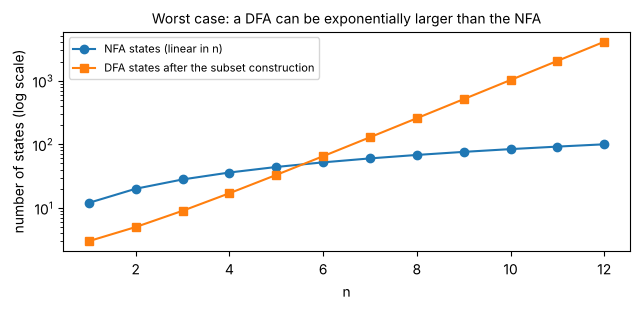

In [4]:
PATTERNS = {
    "date YYYY-MM-DD": r"(19|20)[0-9][0-9]-(0[1-9]|1[0-2])-(0[1-9]|[12][0-9]|3[01])",
    "decimal number": r"-?(0|[1-9][0-9]*)(\.[0-9]+)?",
    "clock HH:MM": r"([01][0-9]|2[0-3]):[0-5][0-9]",
    "identifier": r"[a-z_][a-z0-9_]*",
    "(a|b)*abb": r"(a|b)*abb",
}

def random_accepted(dfa, rng, max_len=14):
    # Walk the DFA at random until an accepting state (give up after max_len characters).
    state, out = 0, ""
    while len(out) < max_len:
        if state in dfa["accepting"] and (not dfa["trans"][state] or rng.random() < 0.3):
            return out
        chars = sorted(dfa["trans"][state])
        ch = chars[int(rng.integers(len(chars)))]
        out += ch; state = dfa["trans"][state][ch]
    return out

rng = np.random.default_rng(0)
DFAS = {}
print("pattern          | NFA states | DFA states | strings | matched by re | disagreements with re.fullmatch")
for name, pattern in PATTERNS.items():
    dfa = DFAS[name] = compile_regex(pattern)
    chars = sorted({ch for row in dfa["trans"] for ch in row})
    tests = []
    for _ in range(2000):
        tests.append("".join(chars[int(i)] for i in rng.integers(len(chars), size=int(rng.integers(0, 12)))))
        s = random_accepted(dfa, rng)
        if s and rng.random() < 0.5:
            j = int(rng.integers(len(s)))
            s = s[:j] + chars[int(rng.integers(len(chars)))] + s[j + 1:]
        tests.append(s)
    truth = [re.fullmatch(pattern, s) is not None for s in tests]
    wrong = sum(dfa_match(dfa, s) != t for s, t in zip(tests, truth))
    print(f"{name:16s} | {dfa['nfa_states']:10d} | {len(dfa['trans']):10d} | {len(tests):7d} | {sum(truth):13d} | {wrong}")

ns, nfa_sizes, dfa_sizes = list(range(1, 13)), [], []
for n in ns:
    dfa = compile_regex("(a|b)*a" + "(a|b)" * (n - 1))
    nfa_sizes.append(dfa["nfa_states"]); dfa_sizes.append(len(dfa["trans"]))
print("\n'the n-th character from the end is a':")
print("  n          " + " ".join(f"{n:5d}" for n in ns))
print("  NFA states " + " ".join(f"{v:5d}" for v in nfa_sizes))
print("  DFA states " + " ".join(f"{v:5d}" for v in dfa_sizes))
print("  2^n        " + " ".join(f"{2 ** n:5d}" for n in ns))

plt.figure(figsize=(6.5, 3.2))
plt.semilogy(ns, nfa_sizes, "o-", label="NFA states (linear in n)")
plt.semilogy(ns, dfa_sizes, "s-", label="DFA states after the subset construction")
plt.xlabel("n"); plt.ylabel("number of states (log scale)")
plt.title("Worst case: a DFA can be exponentially larger than the NFA", fontsize=10)
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4. Tokens are longer than characters: the (state, token) index
A real model does not write characters. It writes **tokens** (session 3), and one token can be several characters long: `20`, `-0`, `ing`. One token can therefore cross several DFA edges, and a token is allowed in a state only if **all** its characters can be read from there.

Checking this at every step means walking every token of the vocabulary through the DFA: with $V$ tokens of mean length $\ell$, about $V \cdot \ell$ character steps **per generated token**. Willard & Louf (2023) observed that the answer depends only on the DFA state, so it can be computed once: for every state, the tokens that are allowed and the state each one leads to. After that, each step of generation is one table lookup.

* Building the index costs at most (DFA states) × (sum of the token lengths) character steps.
* A **trie over the vocabulary** shares the work: tokens with the same first characters are walked together, and a whole subtree is skipped as soon as its prefix cannot be read.

The vocabulary below has the 41 single characters we need plus the 150 most frequent pairs and the 150 most frequent triples of a small text (the story of section 2 and 900 generated dates, numbers and clock times): 341 tokens. A real vocabulary has 50,000 or more.

In [5]:
rng = np.random.default_rng(1)
sample_text = text + " " + " ".join(
    f"{int(rng.integers(1950, 2030))}-{int(rng.integers(1, 13)):02d}-{int(rng.integers(1, 29)):02d} {rng.normal(0, 300):.2f} "
    f"{int(rng.integers(0, 24)):02d}:{int(rng.integers(0, 60)):02d}" for _ in range(300))
singles = sorted(set("0123456789abcdefghijklmnopqrstuvwxyz-.:_ "))
def most_frequent(n_chars, how_many):
    freq = {}
    for i in range(len(sample_text) - n_chars + 1):
        piece = sample_text[i:i + n_chars]
        freq[piece] = freq.get(piece, 0) + 1
    return sorted(freq, key=lambda piece: (-freq[piece], piece))[:how_many]
VOCAB = singles + most_frequent(2, 150) + most_frequent(3, 150)
EOS, BOS = len(VOCAB), len(VOCAB) + 1                        # two special ids: end and start of the output
print(f"vocabulary: {len(VOCAB)} tokens, {sum(map(len, VOCAB))} characters in total; some of them: "
      + " ".join(repr(VOCAB[i]) for i in [0, 12, 45, 60, 100, 200, 230, 300, 340]))

def scan_state(dfa, state):
    # Which tokens can be read from this state, and where does each lead? Walk every token: returns (row, character steps).
    row, n_steps = {}, 0
    for tid, tok in enumerate(VOCAB):
        s = state
        for ch in tok:
            n_steps += 1
            s = dfa["trans"][s].get(ch)
            if s is None:
                break
        if s is not None:
            row[tid] = s
    return row, n_steps

def build_index(dfa):
    rows = [scan_state(dfa, s) for s in range(len(dfa["trans"]))]
    return [r for r, n in rows], sum(n for r, n in rows)

vocab_trie = {}
for tid, tok in enumerate(VOCAB):
    node = vocab_trie
    for ch in tok:
        node = node.setdefault(ch, {})
    node["id"] = tid                                         # a token ends at this node

def build_index_with_trie(dfa):
    index, n_steps = [], 0
    for state in range(len(dfa["trans"])):
        row, stack = {}, [(vocab_trie, state)]
        while stack:                                         # walk the trie and the DFA together
            node, s = stack.pop()
            for ch, child in node.items():
                if ch == "id":
                    row[child] = s
                    continue
                n_steps += 1
                t = dfa["trans"][s].get(ch)
                if t is not None:                            # if not, the whole subtree is skipped
                    stack.append((child, t))
        index.append(row)
    return index, n_steps

print("\npattern          | DFA states | allowed (state, token) pairs | character steps to build: token by token, with the trie")
INDEX = {}
for name, dfa in DFAS.items():
    index, n_plain = build_index(dfa)
    index_trie, n_trie = build_index_with_trie(dfa)
    assert index == index_trie
    INDEX[name] = index
    print(f"{name:16s} | {len(dfa['trans']):10d} | {sum(map(len, index)):7,d} of {len(dfa['trans']) * len(VOCAB):6,d}             | {n_plain:8,d} {n_trie:8,d}")
date_dfa, date_index = DFAS["date YYYY-MM-DD"], INDEX["date YYYY-MM-DD"]
print("\ndate pattern, start state: allowed tokens " + " ".join(repr(VOCAB[t]) for t in sorted(date_index[0])))

vocabulary: 341 tokens, 791 characters in total; some of them: ' ' '9' ' 2' '1-' '8-' '-11' '1-1' '0-1' '3 -'

pattern          | DFA states | allowed (state, token) pairs | character steps to build: token by token, with the trie
date YYYY-MM-DD  |         19 |     419 of  6,479             |    8,519    1,867
decimal number   |          7 |     516 of  2,387             |    3,947    1,213
clock HH:MM      |          8 |     139 of  2,728             |    3,637      801
identifier       |          3 |     262 of  1,023             |    1,610      491
(a|b)*abb        |          5 |      10 of  1,705             |    1,725      220

date pattern, start state: allowed tokens '1' '2' '19' '20' '202' '198' '196' '201' '197' '200' '195' '199'


### 5. Generating dates and numbers that always match
Now the generation loop. The "language model" here is a table of random numbers: for each previous token it gives a fixed random score to each next token. It knows nothing about dates. That is on purpose: the guarantee of constrained decoding comes from the automaton, not from the model.

At each step: look up the tokens allowed in the current DFA state, keep only their scores, take the softmax, sample, and move to the state stored in the index. The end symbol is allowed only in an accepting state.

One more detail makes the outputs **always** complete: a limit on the number of tokens. A breadth-first search on the index gives, for every state, the smallest number of tokens that still reach an accepting state; we never take a token after which the pattern can no longer be finished in the tokens that remain.

We generate 500 strings per pattern, with and without the mask, and check them with `re.fullmatch`. We also count the work: character steps when the vocabulary is scanned at every step, against lookups in the index.

In [6]:
model_scores = np.random.default_rng(2).normal(0.0, 1.0, size=(len(VOCAB) + 2, len(VOCAB) + 2))   # the stand-in model

def tokens_to_accept(dfa, index):
    # dist[s]: the smallest number of tokens that lead from state s to an accepting state.
    # Breadth-first search backwards from the accepting states, over the edges "one token".
    before = [set() for _ in index]
    for s, row in enumerate(index):
        for t in row.values():
            before[t].add(s)
    dist = [math.inf] * len(index)
    queue = sorted(dfa["accepting"])
    for s in queue:
        dist[s] = 0
    while queue:
        t = queue.pop(0)
        for s in before[t]:
            if dist[s] == math.inf:
                dist[s] = dist[t] + 1; queue.append(s)
    return dist

def generate(dfa, rng, max_tokens, lookup=None, dist=None):
    # Sample one output of at most max_tokens tokens. lookup(state) returns ({token: next state}, character steps used);
    # without a lookup the pattern is ignored. Returns (text, number of tokens, character steps).
    state, prev, out, n_steps = 0, BOS, [], 0
    for step in range(max_tokens + 1):
        left = max_tokens - step                             # tokens that may still be written
        if lookup is None:
            allowed = list(range(len(VOCAB) + 1)) if left > 0 else [EOS]
        else:
            row, n = lookup(state); n_steps += n
            allowed = sorted(t for t, nxt in row.items() if dist[nxt] <= left - 1)   # the pattern can still be finished
            if state in dfa["accepting"]:
                allowed.append(EOS)
        z = model_scores[prev, allowed]                      # the model's scores, for the allowed tokens only
        p = np.exp(z - z.max()); p /= p.sum()
        tok = allowed[int(rng.choice(len(allowed), p=p))]
        if tok == EOS:
            break
        out.append(VOCAB[tok]); prev = tok
        if lookup is not None:
            state = row[tok]
    return "".join(out), len(out), n_steps

N_GEN = 500
for name, max_tokens in [("date YYYY-MM-DD", 10), ("decimal number", 6), ("clock HH:MM", 5)]:
    dfa, index = DFAS[name], INDEX[name]
    dist = tokens_to_accept(dfa, index)
    rng = np.random.default_rng(3)
    free = [generate(dfa, rng, max_tokens)[0] for _ in range(N_GEN)]
    rng = np.random.default_rng(3); t0 = time.perf_counter()
    with_index = [generate(dfa, rng, max_tokens, lambda s: (index[s], 0), dist) for _ in range(N_GEN)]
    rng = np.random.default_rng(3); t1 = time.perf_counter()
    with_scan = [generate(dfa, rng, max_tokens, lambda s: scan_state(dfa, s), dist) for _ in range(N_GEN)]
    t2 = time.perf_counter()
    assert [g[0] for g in with_index] == [g[0] for g in with_scan]
    outs = [g[0] for g in with_index]
    n_tokens = sum(g[1] for g in with_index)
    print(f"{name}: at most {max_tokens} tokens, smallest number of tokens that can match: {dist[0]}")
    print(f"  without the mask: {sum(re.fullmatch(dfa['pattern'], s) is not None for s in free)} of {N_GEN} match;  first three: " + "  ".join(repr(s) for s in free[:3]))
    print(f"  with the mask:    {sum(re.fullmatch(dfa['pattern'], s) is not None for s in outs)} of {N_GEN} match;  first six: " + "  ".join(outs[:6]))
    print(f"  work for {N_GEN} outputs ({n_tokens:,d} tokens): scanning the vocabulary at every step, {sum(g[2] for g in with_scan):,d} character steps; "
          f"with the index, {build_index_with_trie(dfa)[1]:,d} character steps once and then {n_tokens + N_GEN:,d} lookups")
    print(f"  time for {N_GEN} outputs: scanning {t2 - t1:.2f} s, with the index {t1 - t0:.2f} s")
    if name.startswith("date"):
        def real_date(s):
            try:
                datetime.date(int(s[:4]), int(s[5:7]), int(s[8:]))
                return True
            except ValueError:
                return False
        bad = [s for s in outs if not real_date(s)]
        print(f"  but {len(bad)} of the {N_GEN} valid strings are not real calendar dates, for example " + ", ".join(bad[:4]))
        print(f"  tokens per date: from {min(g[1] for g in with_index)} to {max(g[1] for g in with_index)}")

date YYYY-MM-DD: at most 10 tokens, smallest number of tokens that can match: 4
  without the mask: 0 of 500 match;  first three: 'u179-01-0y24590221  -'  ' i-47605--285--107-1.6-'  'he.220 624514 a4-09:k'
  with the mask:    500 of 500 match;  first six: 1903-05-18  2010-01-27  2013-05-07  2002-07-23  1999-02-14  2019-02-16
  work for 500 outputs (2,151 tokens): scanning the vocabulary at every step, 1,185,632 character steps; with the index, 1,867 character steps once and then 2,651 lookups
  time for 500 outputs: scanning 0.22 s, with the index 0.06 s
  but 3 of the 500 valid strings are not real calendar dates, for example 1965-02-30, 1974-02-31, 1960-02-30
  tokens per date: from 4 to 6


decimal number: at most 6 tokens, smallest number of tokens that can match: 1
  without the mask: 0 of 500 match;  first three: 'u179-01-0y24'  '3 6 1-2 a7:30'  '21  15:0 th04-21'
  with the mask:    500 of 500 match;  first six: -0.15324318  17308.19608  201201965.3803  -162307768.14  55114737196  400637331268
  work for 500 outputs (2,937 tokens): scanning the vocabulary at every step, 2,067,467 character steps; with the index, 1,213 character steps once and then 3,437 lookups
  time for 500 outputs: scanning 0.33 s, with the index 0.10 s


clock HH:MM: at most 5 tokens, smallest number of tokens that can match: 2
  without the mask: 0 of 500 match;  first three: 'u179-01-0y'  '451--15 19.'  '4:4314 -230:'
  with the mask:    500 of 500 match;  first six: 11:52  11:13  18:15  17:18  08:26  07:12
  work for 500 outputs (1,427 tokens): scanning the vocabulary at every step, 851,023 character steps; with the index, 801 character steps once and then 1,927 lookups
  time for 500 outputs: scanning 0.15 s, with the index 0.04 s


### 6. The mask changes the distribution
Constrained decoding guarantees the **form**. Does it also give us "the model's own answers, minus the invalid ones"? That would be the model's distribution **conditioned** on validity: $P(x \mid x \text{ valid}) = P(x) / \sum_{\text{valid } y} P(y)$. Masking step by step samples from a different distribution.

A small example for the board. A model writes two letters. First letter: `a` 0.5, `b` 0.5. After `a`: `a` 0.9, `b` 0.1. After `b`: `a` 0.5, `b` 0.5. The valid strings are `ab`, `ba` and `bb` (everything except `aa`).

* The model gives them 0.05, 0.25 and 0.25, so the conditional distribution is 0.091, 0.455, 0.455.
* The mask allows both first letters (each can still lead to a valid string) and removes only the second `a` after `a`. So it produces `ab` with probability 0.5, and `ba`, `bb` with 0.25 each.

The mask gives `ab` five and a half times too often: at the first step it cannot know that after `a` the model wants to leave the valid set. Park et al. (2024) analyse this distortion and give an algorithm whose samples approach the conditional distribution, at the cost of more sampling.

We now measure the same effect exactly on the place-name task of section 2: for each of the 31 names, the model's conditional probability and the probability under the mask (both computed by multiplying along the trie, no sampling). The **total variation distance** is half the sum of the absolute differences: 0 means the same distribution, 1 means no overlap.

toy example | model's conditional | step-by-step mask
ab          |               0.091 | 0.500
ba          |               0.455 | 0.250
bb          |               0.455 | 0.250
total variation distance: 0.409

place names: the mask's probabilities add up to 1.000000
total variation distance between the model's conditional distribution and the masked sampler: 0.678
KL divergence (conditional against masked): 1.421 nats
the 2,000 constrained samples of section 2 follow the mask's distribution: largest gap 0.009
name       | conditional |  masked | masked / conditional
sunamganj  |     0.00005 | 0.07776 |   1572.75
bandarban  |     0.00002 | 0.02789 |   1523.53
rangamati  |     0.00000 | 0.00249 |   1392.08
netrokona  |     0.00007 | 0.04534 |    666.16
dhaka      |     0.39741 | 0.04173 |      0.10
khulna     |     0.25290 | 0.04173 |      0.16
pabna      |     0.03389 | 0.00578 |      0.17
bhola      |     0.04009 | 0.01296 |      0.32


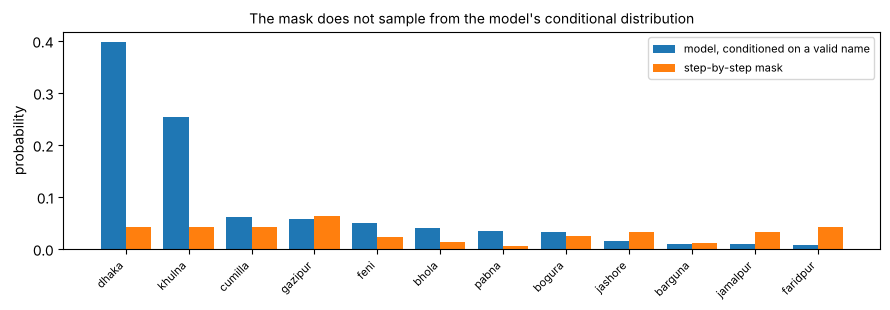

In [7]:
toy_first, toy_second = {"a": 0.5, "b": 0.5}, {"a": {"a": 0.9, "b": 0.1}, "b": {"a": 0.5, "b": 0.5}}
valid = ["ab", "ba", "bb"]
joint = {s: toy_first[s[0]] * toy_second[s[0]][s[1]] for s in valid}
cond = {s: joint[s] / sum(joint.values()) for s in valid}
masked = {}
for s in valid:
    ok_second = [c for c in "ab" if s[0] + c in valid]
    masked[s] = toy_first[s[0]] * toy_second[s[0]][s[1]] / sum(toy_second[s[0]][c] for c in ok_second)
print("toy example | model's conditional | step-by-step mask")
for s in valid:
    print(f"{s:11s} | {cond[s]:19.3f} | {masked[s]:.3f}")
print(f"total variation distance: {0.5 * sum(abs(cond[s] - masked[s]) for s in valid):.3f}")

def mask_prob(name):
    # Exact probability that the trie-constrained sampler of section 2 writes this name.
    a, b, node, p = START[0], START[1], name_trie, 1.0
    for ch in name + END:
        letters = {c: prob[a, b, char_id[c]] for c in node if c != END}
        p_end = prob[a, b, SPACE] + prob[a, b, DOT] if END in node else 0.0
        total = sum(letters.values()) + p_end
        if ch == END:
            return p * p_end / total
        p *= letters[ch] / total
        a, b, node = b, char_id[ch], node[ch]

p_cond = p_model / p_model.sum()                             # the model, conditioned on writing a valid name
p_mask = np.array([mask_prob(n) for n in NAMES])
tv = 0.5 * np.abs(p_cond - p_mask).sum()
kl = float(np.sum(p_cond * np.log(p_cond / p_mask)))
print(f"\nplace names: the mask's probabilities add up to {p_mask.sum():.6f}")
print(f"total variation distance between the model's conditional distribution and the masked sampler: {tv:.3f}")
print(f"KL divergence (conditional against masked): {kl:.3f} nats")
freq = np.array([constrained.count(n) for n in NAMES]) / N_SAMPLES
print(f"the 2,000 constrained samples of section 2 follow the mask's distribution: largest gap {np.abs(freq - p_mask).max():.3f}")
order = np.argsort(p_mask / p_cond)
print("name       | conditional |  masked | masked / conditional")
for i in list(order[-4:][::-1]) + list(order[:4]):
    print(f"{NAMES[i]:10s} | {p_cond[i]:11.5f} | {p_mask[i]:7.5f} | {p_mask[i] / p_cond[i]:9.2f}")

show = np.argsort(-p_cond)[:12]
xs = np.arange(len(show))
plt.figure(figsize=(9, 3.2))
plt.bar(xs - 0.2, p_cond[show], width=0.4, label="model, conditioned on a valid name")
plt.bar(xs + 0.2, p_mask[show], width=0.4, label="step-by-step mask")
plt.xticks(xs, [NAMES[i] for i in show], rotation=45, ha="right", fontsize=8); plt.ylabel("probability")
plt.title("The mask does not sample from the model's conditional distribution", fontsize=10)
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 7. What a finite automaton cannot do: nesting
JSON, program code and arithmetic have **nested** structure: every `[` needs its `]`, to any depth. A finite automaton has a fixed number of states, so it can count only up to a fixed depth. We can write a pattern for "brackets `()` and `[]`, correctly nested, at most $d$ deep", but the DFA must remember which brackets are open. With two kinds of bracket there are $2^{d+1} - 1$ possible stacks of height at most $d$, and every DFA needs at least one state for each (ours is not minimized and has about twice as many).

The right machine has a **stack**: push on an opening bracket, pop on a closing one, and accept only when the stack is empty. A finite automaton plus a stack is a **pushdown automaton**, the machine for context-free grammars. The mask is just as easy: a closing bracket is allowed only if it matches the top of the stack. Engines that guarantee valid JSON are built on this idea; XGrammar, for example, runs a pushdown automaton over bytes (Dong et al. 2024).

The cell compiles the depth-limited pattern for $d = 1 \ldots 7$, tests each DFA on a string nested one level deeper, and then generates 1,000 random strings of up to 40 brackets with the stack mask.

In [8]:
def nested_pattern(depth):
    inner = "" if depth == 1 else nested_pattern(depth - 1)
    return r"(\(" + inner + r"\)|\[" + inner + r"\])*"

print("max depth d | pattern length | NFA states | DFA states | possible stacks | accepts depth d | accepts depth d + 1")
bracket_dfas = {}
for depth in range(1, 8):
    pattern = nested_pattern(depth)
    dfa = bracket_dfas[depth] = compile_regex(pattern)
    deep = lambda k: "([" * (k // 2) + "(" * (k % 2) + ")" * (k % 2) + "])" * (k // 2)
    assert dfa_match(dfa, deep(depth)) == (re.fullmatch(pattern, deep(depth)) is not None)
    print(f"{depth:11d} | {len(pattern):14d} | {dfa['nfa_states']:10d} | {len(dfa['trans']):10d} | {2 ** (depth + 1) - 1:15d} | "
          f"{str(dfa_match(dfa, deep(depth))):15s} | {dfa_match(dfa, deep(depth + 1))}")

PAIR = {"(": ")", "[": "]"}
def stack_mask(stack, left):
    # Characters that keep the string completable when `left` characters may still be written.
    allowed = []
    if stack:
        allowed.append(PAIR[stack[-1]])                      # close the bracket on top of the stack
    if len(stack) + 2 <= left:
        allowed += ["(", "["]                                # open one more only if there is room to close it
    if not stack:
        allowed.append(END)
    return allowed

def is_balanced(s):
    stack = []
    for ch in s:
        if ch in PAIR:
            stack.append(ch)
        elif not stack or PAIR[stack.pop()] != ch:
            return False
    return not stack

rng = np.random.default_rng(4)
MAX_CHARS, strings, depths = 40, [], []
for _ in range(1000):
    stack, out, deepest = [], "", 0
    while True:
        allowed = stack_mask(stack, MAX_CHARS - len(out))
        if END in allowed and (len(allowed) == 1 or rng.random() < 0.1):
            break                                            # the stand-in model stops with probability 0.1 when it may
        brackets = [c for c in allowed if c != END]
        ch = brackets[int(rng.integers(len(brackets)))]      # otherwise any allowed bracket, with equal probability
        out += ch
        if ch in PAIR:
            stack.append(ch); deepest = max(deepest, len(stack))
        else:
            stack.pop()
    strings.append(out); depths.append(deepest)
print(f"\nstack mask: {sum(map(is_balanced, strings))} of {len(strings)} generated strings are balanced; "
      f"longest {max(map(len, strings))} characters, deepest nesting {max(depths)}")
print("  examples: " + "   ".join([s for s in strings if 6 <= len(s) <= 14][:8]))
for depth in [1, 3, 5, 7]:
    print(f"  the depth-{depth} DFA ({len(bracket_dfas[depth]['trans'])} states) accepts {sum(dfa_match(bracket_dfas[depth], s) for s in strings)} of them")

max depth d | pattern length | NFA states | DFA states | possible stacks | accepts depth d | accepts depth d + 1
          1 |             12 |         16 |          5 |               3 | True            | False
          2 |             36 |         52 |         13 |               7 | True            | False
          3 |             84 |        124 |         29 |              15 | True            | False
          4 |            180 |        268 |         61 |              31 | True            | False
          5 |            372 |        556 |        125 |              63 | True            | False
          6 |            756 |       1132 |        253 |             127 | True            | False


          7 |           1524 |       2284 |        509 |             255 | True            | False



stack mask: 1000 of 1000 generated strings are balanced; longest 40 characters, deepest nesting 20
  examples: ([[]])   (())()   [][]()   [(())]   ([[]])   ()()[()()]   [[[]()]]   ()[]()
  the depth-1 DFA (5 states) accepts 152 of them
  the depth-3 DFA (29 states) accepts 180 of them
  the depth-5 DFA (125 states) accepts 201 of them
  the depth-7 DFA (509 states) accepts 253 of them


### 8. The same with a real library (NOT RUN here)
Outlines is an open-source library from the authors of the index method of section 4. The cell below follows its documented interface as of November 2026 (version 1.x: a model object that is called with a prompt and an **output type**). Interfaces of such libraries change quickly; check the current documentation before you run it.

In [ ]:
# NOT RUN: needs `pip install outlines transformers torch` and a model download (run on Kaggle or Colab; a GPU helps).
# Written from the Outlines 1.x documentation as checked in November 2026.
from typing import Literal
import outlines
from outlines.types import Regex
from transformers import AutoModelForCausalLM, AutoTokenizer

name = "<a small open instruction model>"
model = outlines.from_transformers(AutoModelForCausalLM.from_pretrained(name), AutoTokenizer.from_pretrained(name))

# one item of a list (section 2)
district = model("Which district is known for its tea gardens? Answer with one name: ", Literal["dhaka", "sylhet", "khulna"])
# a pattern (sections 3 to 5)
date = model("When did Bangladesh become independent? Answer as YYYY-MM-DD: ",
             Regex(r"(19|20)[0-9][0-9]-(0[1-9]|1[0-2])-(0[1-9]|[12][0-9]|3[01])"), max_new_tokens=12)
print(district, date)                                        # always a valid form; check yourself whether it is the right answer

### 9. Exercises

In [9]:
# TODO: a Bangladeshi mobile number in international form is "+8801", then one digit from 3 to 9, then eight digits.
# Write the pattern with the operators our compiler supports (there is no {8}, so repeat the class), compile it,
# build its index with build_index_with_trie, and generate five numbers with generate(). Check them with re.fullmatch.
# Note: "+" is not in VOCAB yet. What happens to the index if a character of the pattern is in no token? Fix it.
def phone_numbers():
    return None          # replace with your code: return a list of five strings

r = phone_numbers()
print("not done yet" if r is None else r)

not done yet


In [10]:
# TODO: minimize a DFA. Two states are equivalent if they are both accepting or both not, and every character leads
# them to equivalent states (or to no state). Start from the two groups {accepting, not accepting} and split groups
# until nothing changes (Moore's algorithm). Return the number of states of the minimal DFA. Which of the five
# patterns of section 3 shrink? Does the 'n-th character from the end' family shrink?
def minimal_states(dfa):
    return None          # replace with your code

r = minimal_states(DFAS["date YYYY-MM-DD"])
print("not done yet" if r is None else f"date pattern: {len(DFAS['date YYYY-MM-DD']['trans'])} states, minimal {r}")
print(f"runtime so far {time.time() - t_start:.0f} s")

not done yet
runtime so far 3 s


### What to notice
(Written from the saved run. All counts and probabilities are the same on every run, because the seeds are fixed; only the lines that contain the word "time" change.)

1. **A trie answers "what may come next?" in one step.** The five names have 38 letters but the trie has 31 nodes, because prefixes are shared. After `ba` the allowed letters are g, n and r; after `bar` they are g and i.
2. **The mask guarantees the form.** Without the trie, 3 of 2,000 samples were valid district names (the exact probability is 0.0005: this small model almost never writes a whole name correctly). With the trie, 2,000 of 2,000 were valid, and all 31 names appeared. The mask read one trie node at each of the 16,510 steps; testing every symbol against every name would have taken 14,330,680 prefix tests.
3. **Our regular-expression compiler agrees with Python's.** On 4,000 strings for each of five patterns there were 0 disagreements with `re.fullmatch`. The date pattern became 70 NFA states and 19 DFA states. The DFA is usually small, but not always: for "the $n$-th character from the end is `a`" the NFA grew by 8 states per step and the DFA doubled, to 4,097 states at $n = 12$ ($2^n + 1$ here).
4. **The index turns each step into a lookup.** With 341 tokens and the 19 states of the date DFA, only 419 of the 6,479 (state, token) pairs are allowed. Building the index took 8,519 character steps token by token and 1,867 with a trie over the vocabulary. For 500 dates, scanning the vocabulary at every step took 1,185,632 character steps; the index needed its 1,867 steps once and then 2,651 lookups. The saved timings differ by a factor of only three to four, much less than the counts: every step also pays a fixed cost for the softmax and the random draw, and with 341 tokens one scan is only about 450 character steps. The counts show what happens when the vocabulary has 50,000 tokens.
5. **A valid form is not a correct answer.** Without the mask, 0 of 500 outputs of the random "model" matched any pattern; with it, 500 of 500 matched, in 4 to 6 tokens per date. But 3 of the 500 dates do not exist (1965-02-30, 1974-02-31, 1960-02-30): the pattern allows day 31 in every month. And all 500 are random: the automaton knows the format, not the facts.
6. **The mask changes the distribution.** In the two-letter example the total variation distance between the model's conditional distribution and the masked sampler is 0.409. For the 31 names it is 0.678 (KL divergence 1.421 nats). The model itself, asked for a valid name, would say `dhaka` with probability 0.397; the masked sampler says it with 0.042. In the other direction, `sunamganj` has conditional probability 0.00005 but the mask produces it with 0.078, about 1,570 times too often: once the first letters are chosen, the mask forces the remaining letters with probability 1, however unlikely the model finds them. The distortion is this large here because the model puts only 0.05% of its probability on valid names; the more a model already follows the format, the smaller the distortion.
7. **Nesting needs a stack.** The depth-limited bracket patterns gave DFAs of 5, 13, 29, 61, 125, 253 and 509 states for depths 1 to 7, about twice the number of possible stacks, and each one rejected a string nested one level deeper. The stack mask produced 1,000 balanced strings of 1,000, nested up to 20 deep; the depth-7 DFA with its 509 states accepts only 253 of them.
8. **What this lab does not show.** The models here are stand-ins (a trigram model and a table of random scores). With a real model, a real tokenizer and a vocabulary of 50,000 or more tokens, the index is much larger and is built once per pattern; the NOT RUN cell shows the same two tasks with a real library.